3. سوالات تکلیف

In [52]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_linear_data, get_moons_data, get_mnist, get_normalized_mnist
from models import Perceptron, MLP
from train import run_experiment
from plotting import plot_data, show_random_image, plot_multi_training_curves, plot_multi_accuracy_curves

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


3.1. سوالات تحلیل حساسیت

3.1.1. مدل اول: پرسپترون ساده (بدون لایه مخفی - فقط یک نرون با تابع پله) ب

3.1.1.1 داده خطی قابل تفکیک

الف) در چه نرخ یادگیری و چه تعداد دوره، مدل همگرا می شود؟

Train shape: (140, 2)


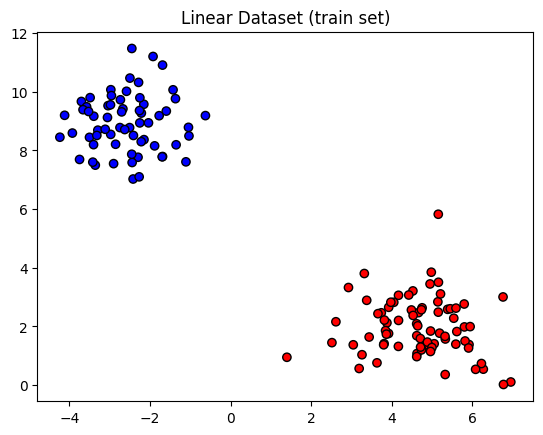

In [23]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_linear_data()

plot_data(X_train,y_train,"Linear Dataset (train set)")

In [ ]:
learning_rates = [1, 0.1, 0.01]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=40,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="blobs_linear",
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]


Epoch 1/40 | Train Loss: 0.3564 Acc: 88.57 | Test Loss: 0.0009 Acc: 100.00
Epoch 5/40 | Train Loss: 0.0012 Acc: 100.00 | Test Loss: 0.0002 Acc: 100.00
Epoch 10/40 | Train Loss: 0.0006 Acc: 100.00 | Test Loss: 0.0001 Acc: 100.00
Epoch 15/40 | Train Loss: 0.0004 Acc: 100.00 | Test Loss: 0.0001 Acc: 100.00
Epoch 20/40 | Train Loss: 0.0003 Acc: 100.00 | Test Loss: 0.0000 Acc: 100.00
Epoch 25/40 | Train Loss: 0.0003 Acc: 100.00 | Test Loss: 0.0000 Acc: 100.00
Epoch 30/40 | Train Loss: 0.0002 Acc: 100.00 | Test Loss: 0.0000 Acc: 100.00
Epoch 35/40 | Train Loss: 0.0002 Acc: 100.00 | Test Loss: 0.0000 Acc: 100.00
Epoch 40/40 | Train Loss: 0.0002 Acc: 100.00 | Test Loss: 0.0000 Acc: 100.00
Epoch 1/40 | Train Loss: 0.1713 Acc: 94.29 | Test Loss: 0.0384 Acc: 100.00
Epoch 5/40 | Train Loss: 0.0192 Acc: 100.00 | Test Loss: 0.0109 Acc: 100.00
Epoch 10/40 | Train Loss: 0.0105 Acc: 100.00 | Test Loss: 0.0058 Acc: 100.00
Epoch 15/40 | Train Loss: 0.0076 Acc: 100.00 | Test Loss: 0.0039 Acc: 100.00
Epoch

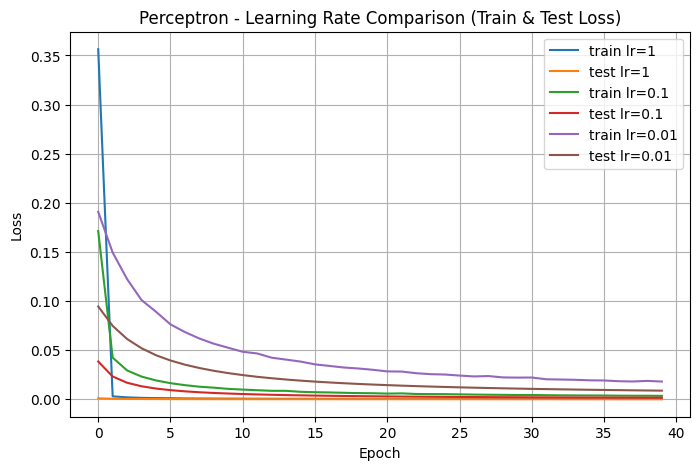

In [25]:
plot_multi_training_curves(
    loss_histories,
    "Perceptron - Learning Rate Comparison (Train & Test Loss)",
    "perceptron_lr_comparison"
)

ب) اگر 5% از برچسب های آموزش را تصادفی عوض کنید (نویز در برچسب)، آیا پرسپترون هنوز همگرا میشود؟ نموداز مرز تصمیم و دقت را نشان دهید

Train shape: (140, 2)


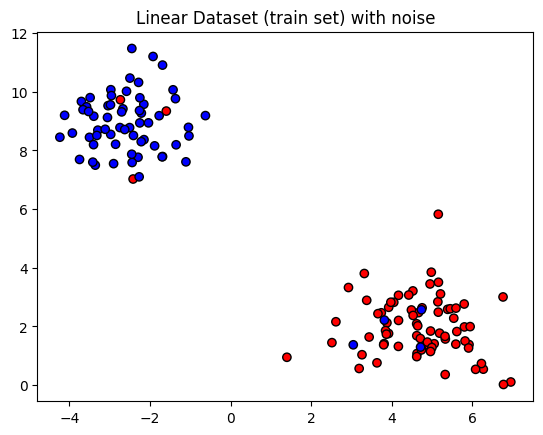

In [26]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_linear_data(noise_rate=0.05)

plot_data(X_train,y_train,"Linear Dataset (train set) with noise")

Epoch 1/50 | Train Loss: 2.4018 Acc: 45.71 | Test Loss: 1.4802 Acc: 61.67
Epoch 5/50 | Train Loss: 0.5141 Acc: 60.00 | Test Loss: 0.2539 Acc: 91.67
Epoch 10/50 | Train Loss: 0.2372 Acc: 95.00 | Test Loss: 0.1044 Acc: 100.00
Epoch 15/50 | Train Loss: 0.2055 Acc: 95.00 | Test Loss: 0.0779 Acc: 100.00
Epoch 20/50 | Train Loss: 0.1970 Acc: 95.00 | Test Loss: 0.0657 Acc: 100.00
Epoch 25/50 | Train Loss: 0.2068 Acc: 95.00 | Test Loss: 0.0594 Acc: 100.00
Epoch 30/50 | Train Loss: 0.1978 Acc: 95.00 | Test Loss: 0.0565 Acc: 100.00
Epoch 35/50 | Train Loss: 0.1914 Acc: 95.00 | Test Loss: 0.0524 Acc: 100.00
Epoch 40/50 | Train Loss: 0.1963 Acc: 95.00 | Test Loss: 0.0515 Acc: 100.00
Epoch 45/50 | Train Loss: 0.1905 Acc: 95.00 | Test Loss: 0.0499 Acc: 100.00
Epoch 50/50 | Train Loss: 0.1907 Acc: 95.00 | Test Loss: 0.0484 Acc: 100.00


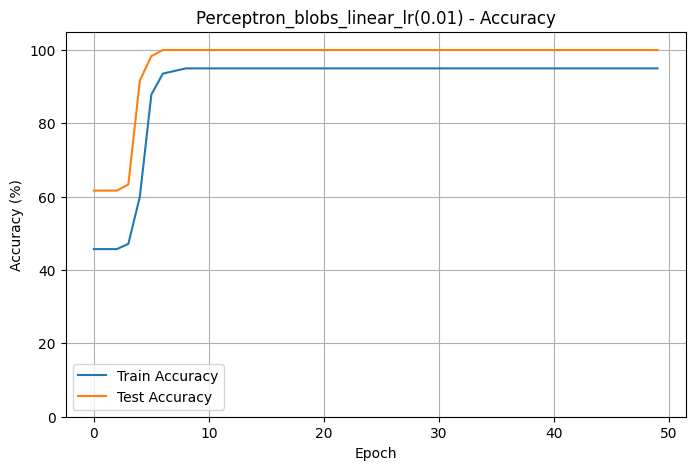

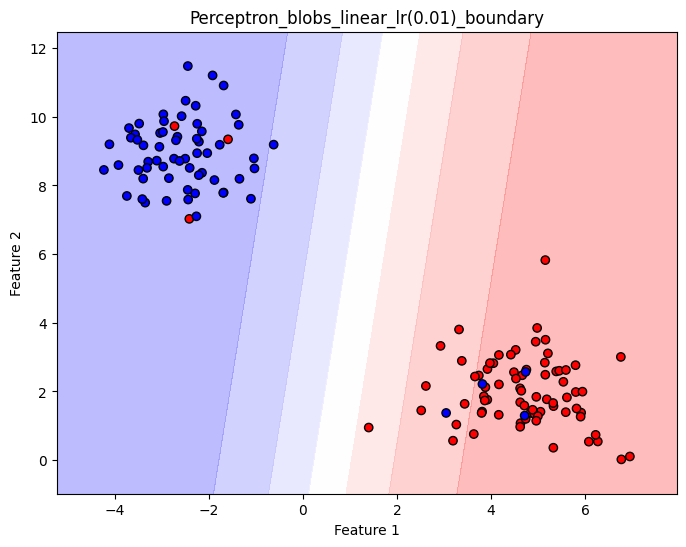

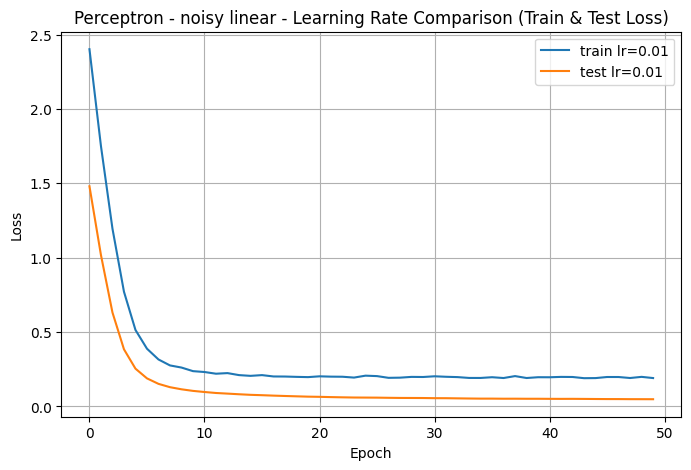

In [31]:
learning_rates = [0.01]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=50,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="blobs_linear",
        plot_decision=True,
        plot_accuracy=True,
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]

plot_multi_training_curves(
    loss_histories,
    "Perceptron - noisy linear - Learning Rate Comparison (Train & Test Loss)",
    "perceptron_lr_comparison"
)    


3.1.1.2 داده غیر خطی (moons)

الف) آیا هرگز به دقت 100% روی داده ی آزمون میرسد؟ چرا؟

Train shape: (140, 2)


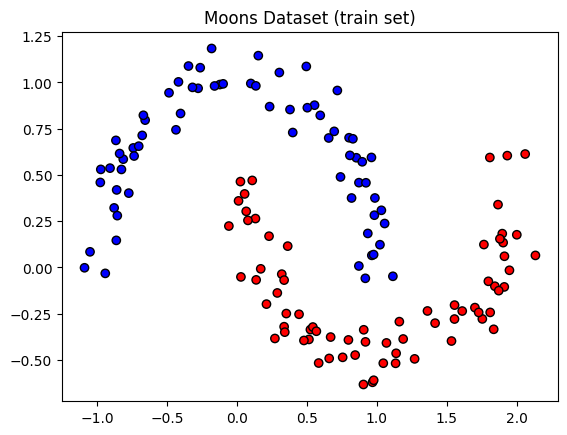

In [32]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_moons_data()

plot_data(X_train,y_train,"Moons Dataset (train set)")

Epoch 1/100 | Train Loss: 0.5032 Acc: 82.14 | Test Loss: 0.4553 Acc: 83.33
Epoch 5/100 | Train Loss: 0.4294 Acc: 81.43 | Test Loss: 0.3831 Acc: 83.33
Epoch 10/100 | Train Loss: 0.3879 Acc: 82.86 | Test Loss: 0.3416 Acc: 83.33
Epoch 15/100 | Train Loss: 0.3683 Acc: 82.86 | Test Loss: 0.3186 Acc: 83.33
Epoch 20/100 | Train Loss: 0.3518 Acc: 83.57 | Test Loss: 0.3038 Acc: 83.33
Epoch 25/100 | Train Loss: 0.3386 Acc: 85.00 | Test Loss: 0.2935 Acc: 83.33
Epoch 30/100 | Train Loss: 0.3339 Acc: 85.71 | Test Loss: 0.2859 Acc: 83.33
Epoch 35/100 | Train Loss: 0.3294 Acc: 85.71 | Test Loss: 0.2803 Acc: 83.33
Epoch 40/100 | Train Loss: 0.3189 Acc: 85.71 | Test Loss: 0.2748 Acc: 83.33
Epoch 45/100 | Train Loss: 0.3180 Acc: 85.71 | Test Loss: 0.2708 Acc: 85.00
Epoch 50/100 | Train Loss: 0.3101 Acc: 85.71 | Test Loss: 0.2671 Acc: 85.00
Epoch 55/100 | Train Loss: 0.3101 Acc: 85.71 | Test Loss: 0.2642 Acc: 85.00
Epoch 60/100 | Train Loss: 0.3082 Acc: 85.71 | Test Loss: 0.2623 Acc: 86.67
Epoch 65/100 |

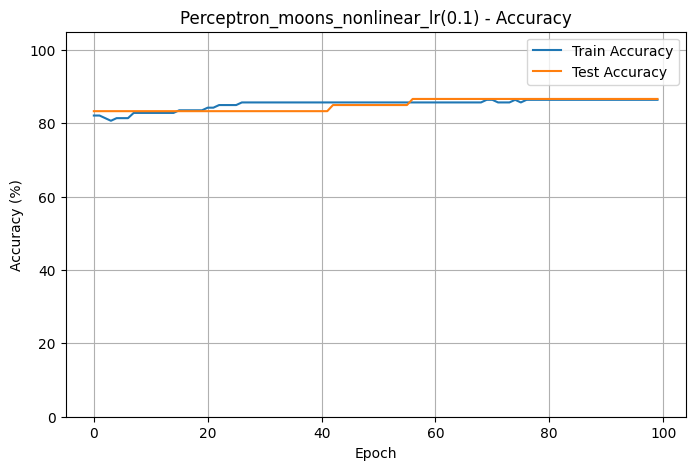

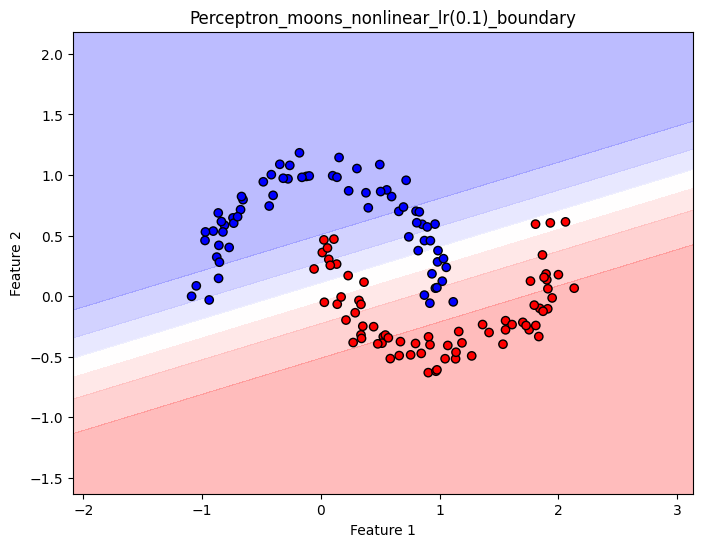

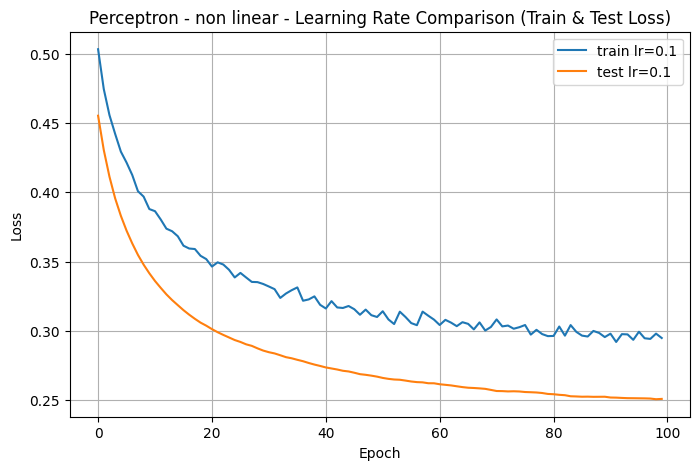

In [35]:
learning_rates = [0.1]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=100,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="moons_nonlinear",
        plot_decision=True,
        plot_accuracy=True,
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]

plot_multi_training_curves(
    loss_histories,
    "Perceptron - non linear - Learning Rate Comparison (Train & Test Loss)",
    "perceptron_lr_comparison"
)    


ب) حداکثر دقتی که میتوانید با تنظیم نرخ یادگیری و تعداد دوره به دست آورید چقدر است؟ این مقدار را با دقت یک دسته بند تصادفی(50%) مقایسه کنید

Epoch 1/100 | Train Loss: 0.6485 Acc: 59.29 | Test Loss: 0.4041 Acc: 83.33
Epoch 5/100 | Train Loss: 0.3344 Acc: 85.71 | Test Loss: 0.2718 Acc: 83.33
Epoch 10/100 | Train Loss: 0.2972 Acc: 85.71 | Test Loss: 0.2518 Acc: 86.67
Epoch 15/100 | Train Loss: 0.2929 Acc: 85.00 | Test Loss: 0.2320 Acc: 88.33
Epoch 20/100 | Train Loss: 0.2882 Acc: 84.29 | Test Loss: 0.2395 Acc: 88.33
Epoch 25/100 | Train Loss: 0.2952 Acc: 84.29 | Test Loss: 0.2428 Acc: 88.33
Epoch 30/100 | Train Loss: 0.2852 Acc: 84.29 | Test Loss: 0.2426 Acc: 88.33
Epoch 35/100 | Train Loss: 0.2905 Acc: 85.00 | Test Loss: 0.2575 Acc: 85.00
Epoch 40/100 | Train Loss: 0.2898 Acc: 84.29 | Test Loss: 0.2398 Acc: 88.33
Epoch 45/100 | Train Loss: 0.2944 Acc: 85.00 | Test Loss: 0.2467 Acc: 86.67
Epoch 50/100 | Train Loss: 0.2876 Acc: 85.00 | Test Loss: 0.2324 Acc: 90.00
Epoch 55/100 | Train Loss: 0.2980 Acc: 85.00 | Test Loss: 0.2525 Acc: 86.67
Epoch 60/100 | Train Loss: 0.2915 Acc: 85.71 | Test Loss: 0.2427 Acc: 86.67
Epoch 65/100 |

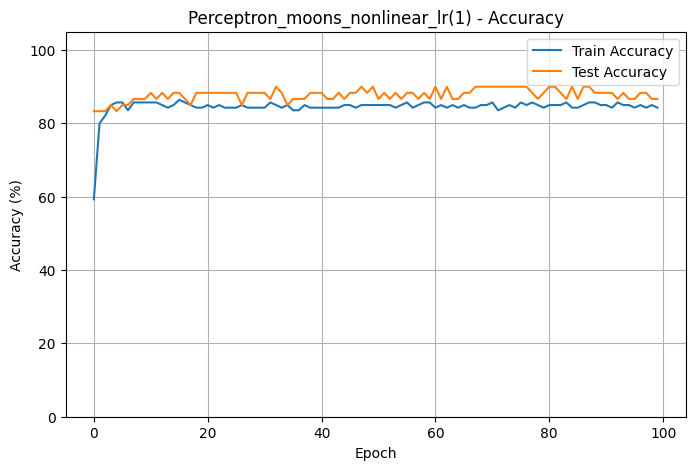

Epoch 1/100 | Train Loss: 0.6471 Acc: 52.14 | Test Loss: 0.6109 Acc: 61.67
Epoch 5/100 | Train Loss: 0.4938 Acc: 78.57 | Test Loss: 0.4476 Acc: 83.33
Epoch 10/100 | Train Loss: 0.4179 Acc: 80.71 | Test Loss: 0.3698 Acc: 83.33
Epoch 15/100 | Train Loss: 0.3782 Acc: 83.57 | Test Loss: 0.3334 Acc: 83.33
Epoch 20/100 | Train Loss: 0.3634 Acc: 84.29 | Test Loss: 0.3136 Acc: 83.33
Epoch 25/100 | Train Loss: 0.3465 Acc: 84.29 | Test Loss: 0.3005 Acc: 83.33
Epoch 30/100 | Train Loss: 0.3358 Acc: 85.71 | Test Loss: 0.2909 Acc: 83.33
Epoch 35/100 | Train Loss: 0.3316 Acc: 85.71 | Test Loss: 0.2828 Acc: 83.33
Epoch 40/100 | Train Loss: 0.3250 Acc: 85.71 | Test Loss: 0.2784 Acc: 83.33
Epoch 45/100 | Train Loss: 0.3193 Acc: 85.71 | Test Loss: 0.2735 Acc: 85.00
Epoch 50/100 | Train Loss: 0.3178 Acc: 85.71 | Test Loss: 0.2699 Acc: 85.00
Epoch 55/100 | Train Loss: 0.3216 Acc: 85.71 | Test Loss: 0.2667 Acc: 85.00
Epoch 60/100 | Train Loss: 0.3043 Acc: 85.71 | Test Loss: 0.2631 Acc: 86.67
Epoch 65/100 |

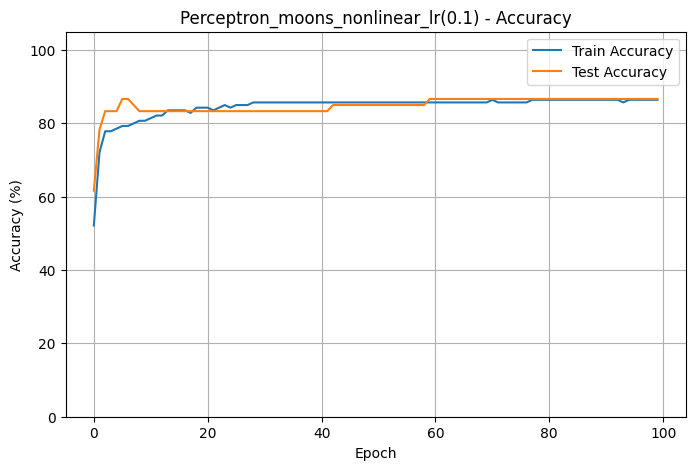

Epoch 1/100 | Train Loss: 0.7374 Acc: 42.14 | Test Loss: 0.6953 Acc: 50.00
Epoch 5/100 | Train Loss: 0.5776 Acc: 83.57 | Test Loss: 0.5459 Acc: 83.33
Epoch 10/100 | Train Loss: 0.4917 Acc: 82.14 | Test Loss: 0.4554 Acc: 83.33
Epoch 15/100 | Train Loss: 0.4495 Acc: 82.14 | Test Loss: 0.4055 Acc: 83.33
Epoch 20/100 | Train Loss: 0.4175 Acc: 82.14 | Test Loss: 0.3735 Acc: 83.33
Epoch 25/100 | Train Loss: 0.3972 Acc: 82.14 | Test Loss: 0.3517 Acc: 83.33
Epoch 30/100 | Train Loss: 0.3837 Acc: 82.86 | Test Loss: 0.3358 Acc: 83.33
Epoch 35/100 | Train Loss: 0.3710 Acc: 82.86 | Test Loss: 0.3241 Acc: 83.33
Epoch 40/100 | Train Loss: 0.3596 Acc: 83.57 | Test Loss: 0.3148 Acc: 83.33
Epoch 45/100 | Train Loss: 0.3568 Acc: 84.29 | Test Loss: 0.3075 Acc: 83.33
Epoch 50/100 | Train Loss: 0.3431 Acc: 85.00 | Test Loss: 0.3011 Acc: 83.33
Epoch 55/100 | Train Loss: 0.3418 Acc: 85.00 | Test Loss: 0.2960 Acc: 83.33
Epoch 60/100 | Train Loss: 0.3346 Acc: 85.71 | Test Loss: 0.2914 Acc: 83.33
Epoch 65/100 |

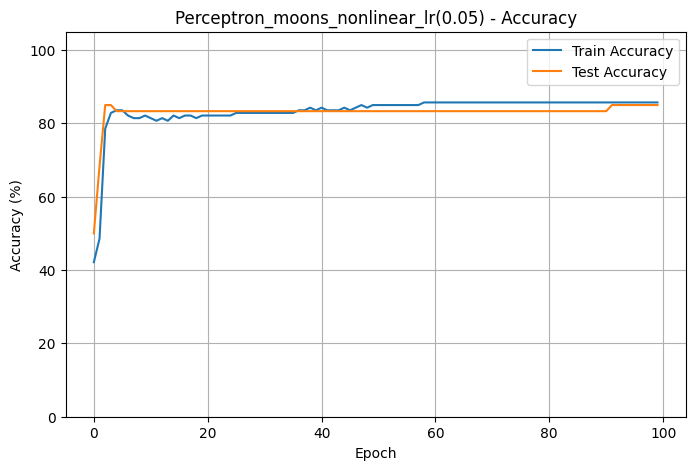

Epoch 1/100 | Train Loss: 0.6674 Acc: 48.57 | Test Loss: 0.6476 Acc: 53.33
Epoch 5/100 | Train Loss: 0.6305 Acc: 67.86 | Test Loss: 0.6119 Acc: 68.33
Epoch 10/100 | Train Loss: 0.5952 Acc: 83.57 | Test Loss: 0.5749 Acc: 83.33
Epoch 15/100 | Train Loss: 0.5661 Acc: 84.29 | Test Loss: 0.5450 Acc: 85.00
Epoch 20/100 | Train Loss: 0.5429 Acc: 83.57 | Test Loss: 0.5196 Acc: 85.00
Epoch 25/100 | Train Loss: 0.5247 Acc: 83.57 | Test Loss: 0.4986 Acc: 83.33
Epoch 30/100 | Train Loss: 0.5061 Acc: 83.57 | Test Loss: 0.4805 Acc: 83.33
Epoch 35/100 | Train Loss: 0.4939 Acc: 82.86 | Test Loss: 0.4647 Acc: 83.33
Epoch 40/100 | Train Loss: 0.4822 Acc: 82.86 | Test Loss: 0.4510 Acc: 83.33
Epoch 45/100 | Train Loss: 0.4708 Acc: 82.86 | Test Loss: 0.4389 Acc: 83.33
Epoch 50/100 | Train Loss: 0.4611 Acc: 82.86 | Test Loss: 0.4280 Acc: 83.33
Epoch 55/100 | Train Loss: 0.4542 Acc: 82.86 | Test Loss: 0.4183 Acc: 83.33
Epoch 60/100 | Train Loss: 0.4473 Acc: 82.86 | Test Loss: 0.4095 Acc: 83.33
Epoch 65/100 |

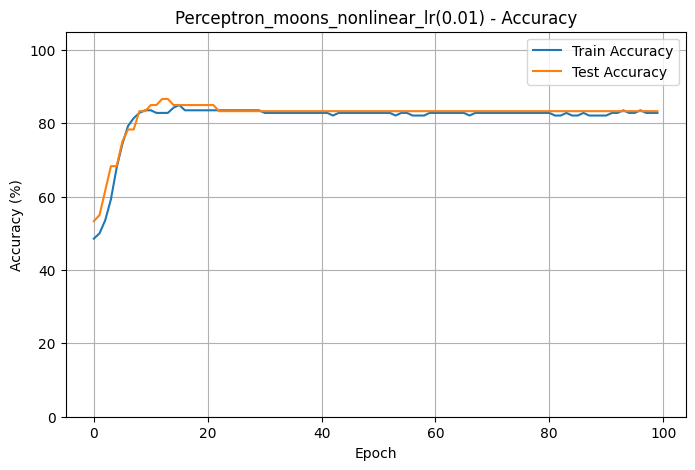

In [39]:
learning_rates = [1,0.1,0.05,0.01]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}
acc_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=100,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="moons_nonlinear",
        plot_accuracy=True,
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]
    acc_histories[f"train lr={lr}"] = result["train_acc"]
    acc_histories[f"test lr={lr}"] = result["test_acc"]


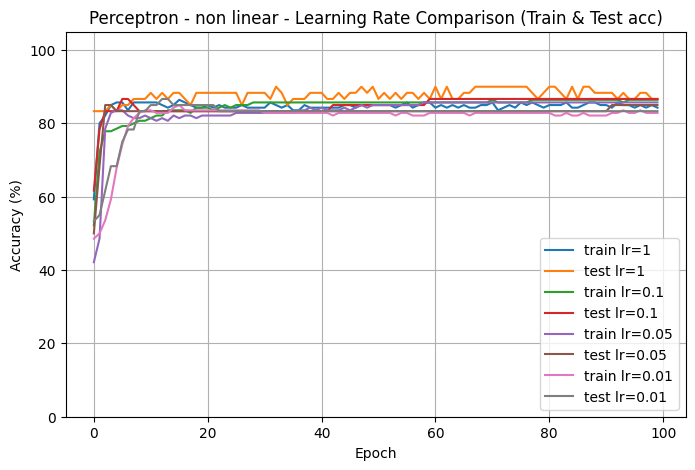

In [40]:
# plot_multi_training_curves(
#     loss_histories,
#     "Perceptron - non linear - Learning Rate Comparison (Train & Test Loss)",
#     "perceptron_lr_comparison"
# )    

plot_multi_accuracy_curves(
    acc_histories,
    "Perceptron - non linear - Learning Rate Comparison (Train & Test acc)",
    "perceptron_lr_comparison"
)    


3.1.1.3. پرسپترون را روی MNIST آموزش دهید

الف) با فرض اینکه هر تصویر را به بردار 784 بعدی(28*28) تبدیل میکنید، آیا پرسپترون قادر به یادگیری است؟
دقت آزمون را گزارش دهید

Train shape: (12665, 28, 28)


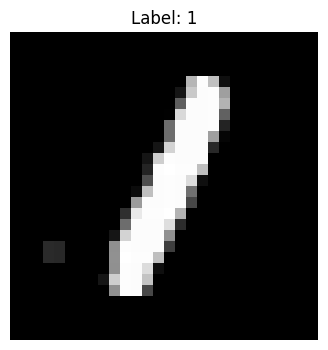

In [44]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist()

show_random_image(X_train, y_train)

In [45]:
learning_rates = [1,0.1,0.01]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}
acc_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=40,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="mnist",
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]
    acc_histories[f"train lr={lr}"] = result["train_acc"]
    acc_histories[f"test lr={lr}"] = result["test_acc"]


Epoch 1/40 | Train Loss: 1066.3853 Acc: 99.51 | Test Loss: 35.0110 Acc: 99.95
Epoch 5/40 | Train Loss: 47.1176 Acc: 99.91 | Test Loss: 65.3536 Acc: 99.91
Epoch 10/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 15/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 20/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 25/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 30/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 35/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 40/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 50.2093 Acc: 99.91
Epoch 1/40 | Train Loss: 24.1117 Acc: 99.60 | Test Loss: 5.6226 Acc: 99.91
Epoch 5/40 | Train Loss: 6.1558 Acc: 99.81 | Test Loss: 6.4359 Acc: 99.81
Epoch 10/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 4.0093 Acc: 99.86
Epoch 15/40 | Train Loss: 0.0000 Acc: 100.00 | Test Loss: 4.0093 Acc: 99.86
Epoch 

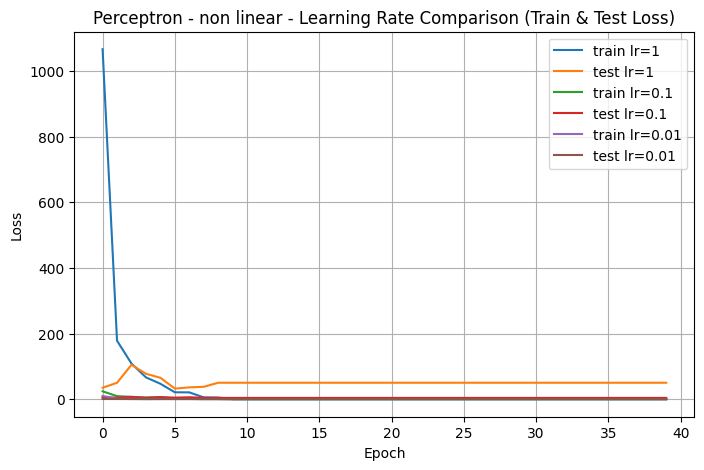

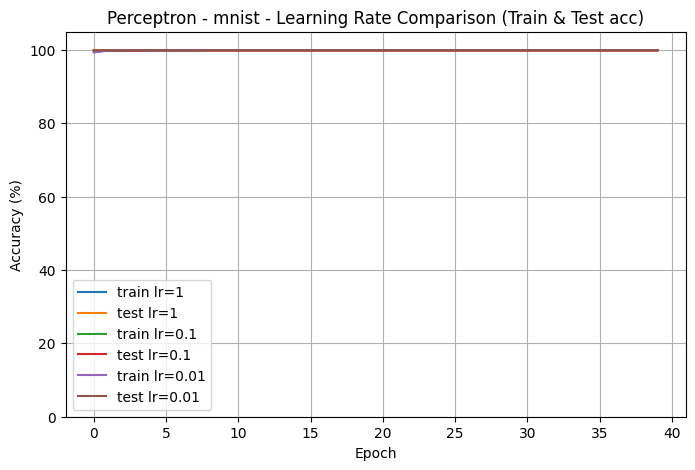

In [ ]:
plot_multi_training_curves(
    loss_histories,
    "Perceptron - minst - Learning Rate Comparison (Train & Test Loss)",
    "perceptron_lr_comparison"
)    

plot_multi_accuracy_curves(
    acc_histories,
    "Perceptron - mnist - Learning Rate Comparison (Train & Test acc)",
    "perceptron_lr_comparison"
)    


ب) آیا نرمال سازی تصاویر(مقسوم بر 255) تاثیری بر سرعت همگرایی دارد؟ دو آزمایش با و بدون نرمال سازی انجام دهید

Train shape: (12665, 1, 28, 28)


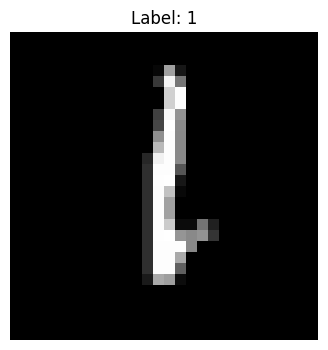

In [48]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_normalized_mnist()

show_random_image(X_train, y_train)

In [49]:
learning_rates = [1,0.1,0.01]
criterion = ["BCEWithLogitsLoss", "BCELoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}
acc_histories = {}

for lr in learning_rates:
    result = run_experiment(
        model_class=Perceptron,
        train_loader=train_loader,
        test_loader=test_loader,
        lr=lr,
        epochs=20,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="normalized_mnist",
        X_vis=X_train,
        y_vis=y_train
    )

    loss_histories[f"train lr={lr}"] = result["train_loss"]
    loss_histories[f"test lr={lr}"] = result["test_loss"]
    acc_histories[f"train lr={lr}"] = result["train_acc"]
    acc_histories[f"test lr={lr}"] = result["test_acc"]


Epoch 1/20 | Train Loss: 0.0121 Acc: 99.51 | Test Loss: 0.0016 Acc: 99.95
Epoch 5/20 | Train Loss: 0.0022 Acc: 99.94 | Test Loss: 0.0022 Acc: 99.95
Epoch 10/20 | Train Loss: 0.0013 Acc: 99.97 | Test Loss: 0.0017 Acc: 99.95
Epoch 15/20 | Train Loss: 0.0009 Acc: 99.98 | Test Loss: 0.0016 Acc: 99.95
Epoch 20/20 | Train Loss: 0.0006 Acc: 100.00 | Test Loss: 0.0016 Acc: 99.95
Epoch 1/20 | Train Loss: 0.0267 Acc: 99.65 | Test Loss: 0.0064 Acc: 99.95
Epoch 5/20 | Train Loss: 0.0053 Acc: 99.87 | Test Loss: 0.0029 Acc: 99.95
Epoch 10/20 | Train Loss: 0.0040 Acc: 99.88 | Test Loss: 0.0024 Acc: 99.95
Epoch 15/20 | Train Loss: 0.0034 Acc: 99.91 | Test Loss: 0.0022 Acc: 99.95
Epoch 20/20 | Train Loss: 0.0030 Acc: 99.92 | Test Loss: 0.0021 Acc: 99.95
Epoch 1/20 | Train Loss: 0.1126 Acc: 99.38 | Test Loss: 0.0355 Acc: 99.86
Epoch 5/20 | Train Loss: 0.0158 Acc: 99.76 | Test Loss: 0.0103 Acc: 99.91
Epoch 10/20 | Train Loss: 0.0105 Acc: 99.77 | Test Loss: 0.0064 Acc: 99.91
Epoch 15/20 | Train Loss: 0.00

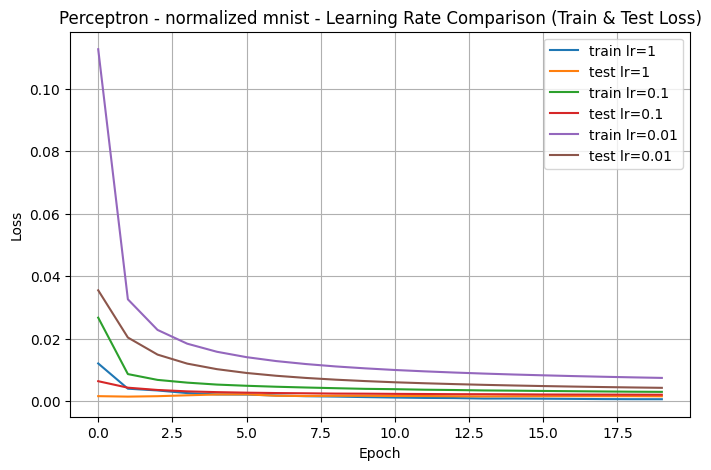

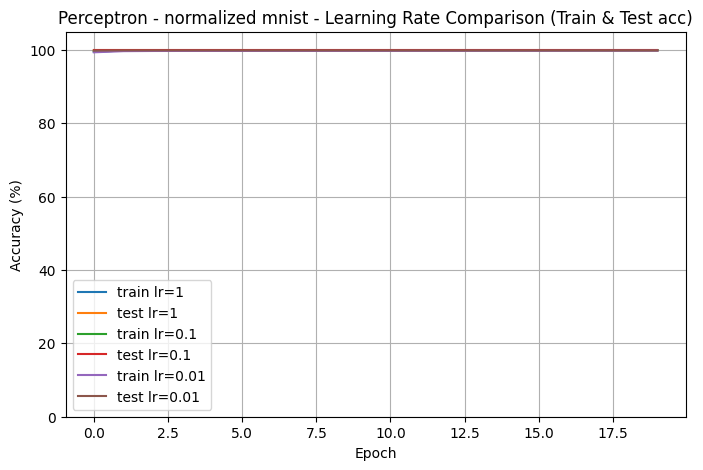

In [50]:
plot_multi_training_curves(
    loss_histories,
    "Perceptron - normalized mnist - Learning Rate Comparison (Train & Test Loss)",
    "perceptron_lr_comparison"
)    

plot_multi_accuracy_curves(
    acc_histories,
    "Perceptron - normalized mnist - Learning Rate Comparison (Train & Test acc)",
    "perceptron_lr_comparison"
)    
